# Stage Rally: Nevado Raura → Cantera Quichas
## Pipeline Integral: Sentinel-2 SR (2.5m) + Fusión SWIR Anti-Nieve + DEM + Snapping Vial 3D (OSM)

**Objetivo del Notebook:**
Generar un paquete de artefactos georreferenciados en **UTM Zona 18S (`EPSG:32718`)** listo para motores de física y BlenderGIS / Godot:
1. **Imagen Satelital Super-Resuelta (2.5 m) y Fusión Espectral SWIR Anti-Nieve:** Usa `SEN2SRLite` (`B04, B03, B02, B08` a 2.5 m) fusionado mediante *Pan-Sharpening* de alta frecuencia con las bandas SWIR (`B11` 1610 nm y `B12` 2190 nm). La nieve absorbe SWIR (se apaga) y la grava/caliza de la carretera en Raura-Quichas refleja fuertemente (resalta con nitidez).
2. **Modelo Digital de Elevación (DEM Copernicus GLO-30):** Descargado directamente desde el catálogo STAC de AWS (`cop-dem-glo-30`), reproyectado y alineado exactamente a la misma caja delimitadora métrica (`EPSG:32718`), exportado en grilla nativa (10 m) y densificada bicúbica C2 (2.5 m) en `float32`.
3. **Extracción y Corrección Horizontal de Carretera (OSM Snapping):** Extrae la ruta entre **Salida (Nevado Raura: `-10.477738, -76.750672`)** y **Llegada (Cantera Quichas: `-10.511513, -76.748641`)**, aplica un filtro tubular Hessiano 2D (Sato) sobre el índice mineral anti-nieve y ajusta el eje horizontal $(X, Y)$ mediante búsqueda en perfil transversal normal + suavizado Savitzky-Golay.
4. **Posicionamiento Vertical 3D sobre el DEM:** Preserva la parametrización longitudinal original del eje OSM e inyecta la elevación $Z$ del DEM suavizado (con desacoplamiento de desplazamientos horizontales), exportando GeoJSON 3D, CSV de telemetría/nodos de spline (`s, x, y, z, grade, curvature`) y metadatos JSON completos.

In [1]:
#@title 0. Parámetros del Tramo (Nevado Raura → Cantera Quichas)
SALIDA_LAT = -10.477738  #@param {type:"number"}
SALIDA_LON = -76.750672  #@param {type:"number"}
LLEGADA_LAT = -10.511513 #@param {type:"number"}
LLEGADA_LON = -76.748641 #@param {type:"number"}

# Centro geométrico automático del tramo (~3.76 km N-S)
PK_LAT = (SALIDA_LAT + LLEGADA_LAT) / 2.0
PK_LON = (SALIDA_LON + LLEGADA_LON) / 2.0

FECHA_INICIO = "2026-05-01"  #@param {type:"date"}
FECHA_FIN = "2026-10-31"     #@param {type:"date"}
LADO_PX = 512                #@param {type:"integer"} # 512 px a 10m = 5.12 x 5.12 km (cubre todo el tramo con margen)
NUBES_MAX_ESCENA = 55        #@param {type:"integer"}
CANDIDATOS_MAX = 100         #@param {type:"integer"}
ESCENAS_PARA_EVALUAR = 18    #@param {type:"integer"}
SOLAPE = 32                  #@param {type:"integer"}

# Parámetros de ajuste vial y muestreo
PASO_SPLINE_M = 5.0          #@param {type:"number"}
RADIO_BUSQUEDA_LATERAL_M = 18.0 #@param {type:"number"}
SALIDA_DIR = "/content/raura_quichas_pipeline_3d" #@param {type:"string"}

assert 256 <= LADO_PX <= 1024, "Se recomienda LADO_PX >= 512 para cubrir los 3.76 km entre Raura y Quichas."
from pathlib import Path
ROOT = Path(SALIDA_DIR)
ROOT.mkdir(parents=True, exist_ok=True)
print(f"Centro del Tramo (WGS84): {PK_LAT:.6f}, {PK_LON:.6f}")
print(f"Cobertura espacial: {LADO_PX*10/1000:.2f} × {LADO_PX*10/1000:.2f} km | Grilla SR: {LADO_PX*4}×{LADO_PX*4} px (2.5 m/px)")

Centro del Tramo (WGS84): -10.494626, -76.749657
Cobertura espacial: 5.12 × 5.12 km | Grilla SR: 2048×2048 px (2.5 m/px)


In [2]:
#@title 1. Instalar dependencias (STAC, Rasterio, SEN2SR, Scikit-Image, OSMnx, GeoPandas)
import sys, subprocess
packages = [
    "pystac-client>=0.8,<1",
    "rasterio>=1.4,<2",
    "pyproj>=3.6,<4",
    "numpy>=1.25,<3",
    "scipy>=1.11",
    "scikit-image>=0.22",
    "matplotlib>=3.7,<4",
    "Pillow>=10,<12",
    "tqdm>=4.66",
    "osmnx>=1.9",
    "geopandas>=0.14",
    "shapely>=2.0",
    "networkx>=3.2",
    "mlstac",
    "sen2sr",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
import torch, rasterio, osmnx as ox, numpy as np
print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| Rasterio:", rasterio.__version__, "| OSMnx:", ox.__version__)

Torch: 2.14.1+cu130 | CUDA: True | Rasterio: 1.5.2 | OSMnx: 2.1.1


In [3]:
#@title 2. Definir Grilla Métrica UTM 18S (EPSG:32718) y Buscar Escenas Sentinel-2 L2A
import math
from pyproj import Transformer
from rasterio.transform import from_origin, Affine
from rasterio.warp import transform_bounds
from pystac_client import Client

STAC_URL = "https://earth-search.aws.element84.com/v1"
COLECCION_S2 = "sentinel-2-c1-l2a"
COLECCION_DEM = "cop-dem-glo-30"
CRS_METRICO = "EPSG:32718"  # UTM Zone 18S (Perú Central)
RES_10M = 10.0
RES_SR = 2.5

wgs_to_utm = Transformer.from_crs("EPSG:4326", CRS_METRICO, always_xy=True)
utm_to_wgs = Transformer.from_crs(CRS_METRICO, "EPSG:4326", always_xy=True)

centro_x, centro_y = wgs_to_utm.transform(PK_LON, PK_LAT)
salida_x, salida_y = wgs_to_utm.transform(SALIDA_LON, SALIDA_LAT)
llegada_x, llegada_y = wgs_to_utm.transform(LLEGADA_LON, LLEGADA_LAT)

x_izq = math.floor((centro_x - (LADO_PX * RES_10M / 2.0)) / RES_10M) * RES_10M
y_arriba = math.ceil((centro_y + (LADO_PX * RES_10M / 2.0)) / RES_10M) * RES_10M
x_der = x_izq + LADO_PX * RES_10M
y_abajo = y_arriba - LADO_PX * RES_10M

transform_10m = from_origin(x_izq, y_arriba, RES_10M, RES_10M)
transform_2p5m = transform_10m * Affine.scale(1/4, 1/4)
bbox_wgs84 = transform_bounds(CRS_METRICO, "EPSG:4326", x_izq, y_abajo, x_der, y_arriba, densify_pts=21)

assert x_izq < salida_x < x_der and y_abajo < salida_y < y_arriba, "Punto de Salida fuera del recorte. Incrementa LADO_PX."
assert x_izq < llegada_x < x_der and y_abajo < llegada_y < y_arriba, "Punto de Llegada fuera del recorte. Incrementa LADO_PX."

client = Client.open(STAC_URL)
search = client.search(
    collections=[COLECCION_S2],
    bbox=list(bbox_wgs84),
    datetime=f"{FECHA_INICIO}T00:00:00Z/{FECHA_FIN}T23:59:59Z",
    query={"eo:cloud_cover": {"lte": NUBES_MAX_ESCENA}},
    max_items=CANDIDATOS_MAX,
)
escenas = list(search.items())
if not escenas:
    raise RuntimeError("Sin escenas en el rango indicado. Amplía fechas o sube NUBES_MAX_ESCENA.")

escenas.sort(key=lambda x: (float(x.properties.get("eo:cloud_cover", 100)), str(x.properties.get("datetime", ""))))
print(f"Escenas candidatas: {len(escenas)} | BBOX UTM 18S: [{x_izq:.1f}, {y_abajo:.1f}, {x_der:.1f}, {y_arriba:.1f}]")

Escenas candidatas: 100 | BBOX UTM 18S: [305950.0, 8836810.0, 311070.0, 8841930.0]


In [4]:
#@title 3. Evaluar SCL Local y Seleccionar la Escena Óptima (Conservando Nieve Clase 11)
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

GDAL_OPTS = dict(
    GDAL_DISABLE_READDIR_ON_OPEN="YES",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.TIF",
    GDAL_HTTP_MAX_RETRY="4",
    GDAL_HTTP_RETRY_DELAY="1",
)

def leer_asset_utm(item, asset_key, transform_dst, width_dst, height_dst, metodo=Resampling.nearest):
    if asset_key not in item.assets:
        raise KeyError(f"{asset_key} no disponible en {item.id}")
    href = item.assets[asset_key].href
    with rasterio.Env(**GDAL_OPTS):
        with rasterio.open(href) as src:
            with WarpedVRT(
                src, crs=CRS_METRICO, transform=transform_dst,
                width=width_dst, height=height_dst, resampling=metodo,
                src_nodata=src.nodata,
            ) as vrt:
                return vrt.read(1, masked=True).filled(0)

calificaciones = []
for item in escenas[:ESCENAS_PARA_EVALUAR]:
    try:
        scl = leer_asset_utm(item, "scl", transform_10m, LADO_PX, LADO_PX, Resampling.nearest).astype("uint8")
        valido = ~np.isin(scl, [0, 1])
        valid_pct = 100.0 * float(valido.mean())
        nubes_local = 100.0 * float(np.isin(scl, [3, 8, 9, 10]).mean())
        no_clasificado = 100.0 * float((scl == 7).mean())
        nieve_local = 100.0 * float((scl == 11).mean())
        glob = float(item.properties.get("eo:cloud_cover", 100))
        puntaje = nubes_local + (100.0 - valid_pct) * 2.0 + 0.08 * glob + 0.15 * no_clasificado
        calificaciones.append((puntaje, item, scl, nubes_local, valid_pct, nieve_local, no_clasificado))
        print(f"{item.datetime.date()} | nubes_loc={nubes_local:5.1f}% | válido={valid_pct:5.1f}% | nieve={nieve_local:5.1f}% | score={puntaje:6.1f}")
    except Exception as err:
        print("Error leyendo", item.id, "->", str(err)[:120])

calificaciones_validas = [c for c in calificaciones if c[4] >= 95.0]
if not calificaciones_validas:
    raise RuntimeError("Ninguna escena cubre >= 95% del AOI.")
calificaciones_validas.sort(key=lambda t: t[0])
score, seleccionado, SCL, NUBES_LOCAL, COBERTURA_LOCAL, NIEVE_LOCAL, NO_CLASIFICADO = calificaciones_validas[0]
fecha_str = seleccionado.datetime.strftime("%Y%m%d")
prefix = f"raura_quichas_{fecha_str}_{seleccionado.id.replace('/', '_')}"
print(f"\n---> ESCENA ELEGIDA: {seleccionado.id} ({seleccionado.datetime.isoformat()}) | Nubes: {NUBES_LOCAL:.2f}% | Nieve: {NIEVE_LOCAL:.2f}%")

2026-08-07 | nubes_loc=  0.0% | válido= 99.9% | nieve= 13.0% | score=   0.3
2026-07-26 | nubes_loc=  0.5% | válido= 87.6% | nieve=  7.7% | score=  25.4
2026-08-04 | nubes_loc=  0.0% | válido= 74.8% | nieve=  1.5% | score=  50.4
2026-10-03 | nubes_loc=  0.0% | válido= 74.8% | nieve=  1.4% | score=  50.4
2026-08-07 | nubes_loc=  0.0% | válido= 74.8% | nieve=  1.5% | score=  50.4
2026-10-01 | nubes_loc=  0.0% | válido= 74.8% | nieve=  1.4% | score=  50.4
2026-10-13 | nubes_loc=  0.0% | válido= 74.8% | nieve=  1.2% | score=  50.4
2026-10-04 | nubes_loc=  0.2% | válido= 73.4% | nieve=  2.4% | score=  53.5
2026-07-21 | nubes_loc=  0.0% | válido= 74.8% | nieve=  1.6% | score=  50.4
2026-07-21 | nubes_loc=  0.0% | válido= 97.3% | nieve= 12.5% | score=   5.4
2026-08-07 | nubes_loc=  0.0% | válido=100.0% | nieve= 12.5% | score=   0.1
2026-10-06 | nubes_loc=  0.0% | válido= 87.9% | nieve=  8.0% | score=  24.3
2026-10-06 | nubes_loc=  0.0% | válido= 74.8% | nieve=  1.4% | score=  50.4
2026-10-09 |

In [5]:
#@title 4. Descargar Bandas Ópticas 10m (RGBN) + Bandas SWIR 20m (B11, B12) para Separación de Nieve
BANDAS_10M = [("red", "B04"), ("green", "B03"), ("blue", "B02"), ("nir", "B08")]
BANDAS_SWIR = [("swir16", "B11"), ("swir22", "B12")]

metadatos_radiometricos = {}

def cargar_stack_reflectancia(item, lista_bandas, metodo_resampling):
    capas = []
    for asset_name, band_name in lista_bandas:
        dn_arr = leer_asset_utm(item, asset_name, transform_10m, LADO_PX, LADO_PX, metodo_resampling).astype("float32")
        rb = item.assets[asset_name].extra_fields.get("raster:bands", [{}])[0]
        scale = float(rb.get("scale", 0.0001))
        offset = float(rb.get("offset", 0.0))
        metadatos_radiometricos[band_name] = {"scale": scale, "offset": offset, "asset": asset_name}
        refl = np.clip(dn_arr * scale + offset, 0.0, 1.0)
        capas.append(refl)
        print(f"{band_name} ({asset_name}): reflectancia = DN * {scale:g} + {offset:g}")
    return np.stack(capas, axis=0).astype("float32")

x_s2 = cargar_stack_reflectancia(seleccionado, BANDAS_10M, Resampling.bilinear)
x_swir_10m = cargar_stack_reflectancia(seleccionado, BANDAS_SWIR, Resampling.cubic)

mascara_invalida = ~np.isin(SCL, [2, 3, 4, 5, 6, 7, 8, 9, 10, 11])
x_s2[:, mascara_invalida] = 0.0
x_swir_10m[:, mascara_invalida] = 0.0
print("Shape RGBN 10m:", x_s2.shape, "| Shape SWIR remuestreado 10m:", x_swir_10m.shape)

B04 (red): reflectancia = DN * 0.0001 + -0.1
B03 (green): reflectancia = DN * 0.0001 + -0.1
B02 (blue): reflectancia = DN * 0.0001 + -0.1
B08 (nir): reflectancia = DN * 0.0001 + -0.1
B11 (swir16): reflectancia = DN * 0.0001 + -0.1
B12 (swir22): reflectancia = DN * 0.0001 + -0.1
Shape RGBN 10m: (4, 512, 512) | Shape SWIR remuestreado 10m: (2, 512, 512)


In [10]:
#@title 5. Descargar y Alinear DEM (Copernicus GLO-30) a las Grillas de 10 m y 2.5 m
import os
import scipy.ndimage as ndi

os.environ["AWS_NO_SIGN_REQUEST"] = "YES"
os.environ["AWS_S3_ENDPOINT"] = "s3.amazonaws.com"
GDAL_OPTS["AWS_NO_SIGN_REQUEST"] = "YES"

def leer_dem_utm(item, asset_key, transform_dst, width_dst, height_dst, metodo=Resampling.bilinear):
    href = item.assets[asset_key].href
    if href.startswith("s3://copernicus-dem-30m/"):
        href = href.replace("s3://copernicus-dem-30m/", "https://copernicus-dem-30m.s3.amazonaws.com/")

    with rasterio.Env(**GDAL_OPTS):
        with rasterio.open(href) as src:
            with WarpedVRT(
                src, crs=CRS_METRICO, transform=transform_dst,
                width=width_dst, height=height_dst, resampling=metodo,
                src_nodata=src.nodata,
            ) as vrt:
                return vrt.read(1, masked=True).filled(np.nan)

search_dem = client.search(collections=[COLECCION_DEM], bbox=list(bbox_wgs84))
items_dem = list(search_dem.items())
if not items_dem:
    raise RuntimeError("No se encontraron teselas de Copernicus DEM GLO-30 para el área.")

print(f"Teselas DEM encontradas: {[it.id for it in items_dem]}")

dem_10m_acum = np.zeros((LADO_PX, LADO_PX), dtype="float32")
peso_10m = np.zeros((LADO_PX, LADO_PX), dtype="float32")

for it in items_dem:
    asset_key = "data" if "data" in it.assets else list(it.assets.keys())[0]
    arr_dem = leer_dem_utm(it, asset_key, transform_10m, LADO_PX, LADO_PX, Resampling.bilinear).astype("float32")
    mask_val = (~np.isnan(arr_dem)) & (arr_dem > -100.0)
    dem_10m_acum[mask_val] += arr_dem[mask_val]
    peso_10m[mask_val] += 1.0

dem_10m = np.where(peso_10m > 0, dem_10m_acum / np.maximum(peso_10m, 1.0), np.nan).astype("float32")
if np.isnan(dem_10m).any():
    mediana_z = float(np.nanmedian(dem_10m))
    dem_10m = np.nan_to_num(dem_10m, nan=mediana_z)

dem_2p5m_raw = ndi.zoom(dem_10m, 4, order=3).astype("float32")
dem_2p5m = ndi.gaussian_filter(dem_2p5m_raw, sigma=1.2).astype("float32")

print(f"DEM alineado -> Altitud Mín: {dem_2p5m.min():.1f} msnm | Máx: {dem_2p5m.max():.1f} msnm | Media: {dem_2p5m.mean():.1f} msnm")

Teselas DEM encontradas: ['Copernicus_DSM_COG_10_S11_00_W077_00_DEM']
DEM alineado -> Altitud Mín: 4219.6 msnm | Máx: 5554.8 msnm | Media: 4718.2 msnm


In [11]:
#@title 6. Super-Resolución SEN2SRLite ×4 (2.5 m) y Fusión Espectral SWIR Anti-Nieve
import torch
import mlstac
import sen2sr
from skimage.filters import sato
from skimage.exposure import equalize_adapthist

MODELO_URL = "https://huggingface.co/tacofoundation/sen2sr/resolve/main/SEN2SRLite/NonReference_RGBN_x4/mlm.json"
MODELO_DIR = ROOT / "modelo_sen2srlite_rgbn"
MODELO_DIR.mkdir(parents=True, exist_ok=True)
mlstac.download(file=MODELO_URL, output_dir=str(MODELO_DIR))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo = mlstac.load(str(MODELO_DIR)).compiled_model(device=device).to(device).eval()
X_tensor = torch.from_numpy(np.nan_to_num(x_s2, nan=0.0, posinf=0.0, neginf=0.0)).to(device)

with torch.inference_mode():
    sr_torch = sen2sr.predict_large(model=modelo, X=X_tensor, overlap=SOLAPE)

sr = np.clip(np.nan_to_num(sr_torch.cpu().float().numpy(), nan=0.0, posinf=0.0, neginf=0.0), 0.0, 1.0).astype("float32")
R_hr, G_hr, B_hr, NIR_hr = sr[0], sr[1], sr[2], sr[3]

# --- FUSIÓN SWIR A 2.5m (PAN-SHARPENING CON ALTA FRECUENCIA DE SR) ---
swir_2p5m = ndi.zoom(x_swir_10m, (1, 4, 4), order=3)
B11_hr, B12_hr = np.clip(swir_2p5m[0], 0.0, 1.0), np.clip(swir_2p5m[1], 0.0, 1.0)

lum_hr = (R_hr + G_hr + B_hr + NIR_hr) * 0.25
lum_low = ndi.gaussian_filter(lum_hr, sigma=2.5) + 1e-6
modulador_hf = np.clip(lum_hr / lum_low, 0.5, 2.0)

B11_sharp = np.clip(B11_hr * modulador_hf, 0.0, 1.0).astype("float32")
B12_sharp = np.clip(B12_hr * modulador_hf, 0.0, 1.0).astype("float32")

# --- ÍNDICES FÍSICOS A 2.5m ---
eps = 1e-6
ndsi_2p5m = ((G_hr - B11_sharp) / (G_hr + B11_sharp + eps)).astype("float32") # Nieve > 0.40, Camino < 0.15
ndvi_2p5m = ((NIR_hr - R_hr) / (NIR_hr + R_hr + eps)).astype("float32")       # Vegetación > 0.25
ndwi_2p5m = ((G_hr - NIR_hr) / (G_hr + NIR_hr + eps)).astype("float32")       # Agua > 0.15

# --- IMAGEN MEJORADA ANTI-NIEVE (FALSO COLOR B12 - B11 - B02 + REALCE MINERAL) ---
def generar_composicion_vial_nitida(b12, b11, r, g, b):
    # R=B12 (Roca/Caliza/Camino brillante), G=B11 (Suelo), B=B02 (Nieve se vuelve azul cian oscuro)
    comp = np.stack([b12 * 0.7 + r * 0.3, b11 * 0.7 + g * 0.3, b], axis=-1)
    p2, p98 = np.percentile(comp, (1.5, 98.5), axis=(0, 1))
    comp_norm = np.clip((comp - p2) / (p98 - p2 + eps), 0.0, 1.0)
    for c in range(3):
        comp_norm[..., c] = equalize_adapthist(comp_norm[..., c], clip_limit=0.018)
    return comp_norm.astype("float32")

img_antinieve_rgb = generar_composicion_vial_nitida(B12_sharp, B11_sharp, R_hr, G_hr, B_hr)

# --- PROBABILIDAD RADIOMÉTRICA Y TOPOLÓGICA DE CARRETERA (FILTRO SATO HESSIANO 2D) ---
w_no_nieve = np.clip(1.0 - np.clip((ndsi_2p5m - 0.08) / 0.32, 0.0, 1.0), 0.0, 1.0)
w_no_agua  = np.clip(1.0 - np.clip((ndwi_2p5m - 0.05) / 0.20, 0.0, 1.0), 0.0, 1.0)
w_no_veg   = np.clip(1.0 - np.clip((ndvi_2p5m - 0.22) / 0.25, 0.0, 1.0), 0.0, 1.0)

reflectancia_vial = (0.45 * B11_sharp + 0.35 * B12_sharp + 0.20 * R_hr) * w_no_nieve * w_no_agua * w_no_veg
reflectancia_vial = (reflectancia_vial - reflectancia_vial.min()) / (reflectancia_vial.max() - reflectancia_vial.min() + eps)

# Filtro tubular multiescala para anchos de vía de 4m a 12m (en píxeles de 2.5m -> sigmas 0.8 a 2.4)
energia_tubular = sato(reflectancia_vial, sigmas=[0.8, 1.3, 1.9, 2.5], black_ridges=False).astype("float32")
energia_tubular = (energia_tubular - energia_tubular.min()) / (energia_tubular.max() - energia_tubular.min() + eps)

mapa_energia_camino = np.clip(0.40 * reflectancia_vial + 0.60 * energia_tubular, 0.0, 1.0).astype("float32")
print("Fusión SWIR + SR 2.5m y Mapa de Energía Vial completados.")

100%|██████████| 36/36 [00:02<00:00, 12.64it/s]


Fusión SWIR + SR 2.5m y Mapa de Energía Vial completados.


In [12]:
#@title 7. Extracción de Carretera OSM, Corrección Longitudinal/Horizontal y Posicionamiento 3D en DEM
import networkx as nx
import geopandas as gpd
from shapely.geometry import LineString, Point
from scipy.signal import savgol_filter
from scipy.ndimage import map_coordinates

inv_transform_2p5m = ~transform_2p5m

# 1. Descargar red vial OSM en el área y calcular ruta entre Salida (Raura) y Llegada (Quichas)
G_osm = ox.graph_from_bbox(bbox=bbox_wgs84, network_type="all", simplify=False, retain_all=True)
G_utm = ox.project_graph(G_osm, to_crs=CRS_METRICO)

# Usar grafo no dirigido para asegurar conectividad sin importar el sentido de las vías mineras en OSM
G_undir = G_utm.to_undirected()
nodo_orig = ox.distance.nearest_nodes(G_utm, X=salida_x, Y=salida_y)
nodo_dest = ox.distance.nearest_nodes(G_utm, X=llegada_x, Y=llegada_y)

ruta_nodos = nx.shortest_path(G_undir, nodo_orig, nodo_dest, weight="length")

coords_osm = []
for u, v in zip(ruta_nodos[:-1], ruta_nodos[1:]):
    ed = min(G_undir.get_edge_data(u, v).values(), key=lambda d: d.get("length", 0))
    if "geometry" in ed:
        pts_seg = list(ed["geometry"].coords)
        # Asegurar orientación correcta del segmento de u -> v
        ux, uy = G_undir.nodes[u]["x"], G_undir.nodes[u]["y"]
        if math.hypot(pts_seg[0][0] - ux, pts_seg[0][1] - uy) > math.hypot(pts_seg[-1][0] - ux, pts_seg[-1][1] - uy):
            pts_seg = pts_seg[::-1]
    else:
        pts_seg = [(G_undir.nodes[u]["x"], G_undir.nodes[u]["y"]), (G_undir.nodes[v]["x"], G_undir.nodes[v]["y"])]
    if coords_osm and pts_seg[0] == coords_osm[-1]:
        coords_osm.extend(pts_seg[1:])
    else:
        coords_osm.extend(pts_seg)

linea_osm_2d = LineString(coords_osm)
print(f"Ruta OSM base extraída -> Longitud 2D: {linea_osm_2d.length / 1000.0:.3f} km | Vértices crudos: {len(coords_osm)}")

# 2. Remuestreo uniforme en `s` y Snapping Transversal Guiado sobre `mapa_energia_camino`
s_dist = np.arange(0.0, linea_osm_2d.length, PASO_SPLINE_M)
if s_dist[-1] < linea_osm_2d.length:
    s_dist = np.append(s_dist, linea_osm_2d.length)

pts_osm = np.array([[linea_osm_2d.interpolate(d).x, linea_osm_2d.interpolate(d).y] for d in s_dist], dtype="float64")

# Tangentes y normales unitarias
grad_xy = np.gradient(pts_osm, axis=0)
norm_grad = np.linalg.norm(grad_xy, axis=1, keepdims=True) + 1e-9
tangentes = grad_xy / norm_grad
normales = np.column_stack([-tangentes[:, 1], tangentes[:, 0]])

offsets_m = np.arange(-RADIO_BUSQUEDA_LATERAL_M, RADIO_BUSQUEDA_LATERAL_M + 0.5, 0.5)
prior_gauss = np.exp(-0.5 * (offsets_m / (RADIO_BUSQUEDA_LATERAL_M * 0.65)) ** 2)

delta_normal_opt = np.zeros(len(pts_osm), dtype="float64")
confianza_vial = np.zeros(len(pts_osm), dtype="float32")

for i, (pt, n_vec) in enumerate(zip(pts_osm, normales)):
    cand_xy = pt[None, :] + offsets_m[:, None] * n_vec[None, :]
    cols, rows = inv_transform_2p5m * (cand_xy[:, 0], cand_xy[:, 1])
    vals = map_coordinates(mapa_energia_camino, [rows, cols], order=1, mode="nearest")
    score = vals * prior_gauss
    idx_max = int(np.argmax(score))
    confianza_vial[i] = float(vals[idx_max])
    if vals[idx_max] > 0.12:
        delta_normal_opt[i] = offsets_m[idx_max]

# Anclar suavemente el inicio y fin exactos del tramo y filtrar con Savitzky-Golay para continuidad C2
win_sg = min(25, (len(pts_osm) // 2) * 2 - 1)
delta_normal_suave = savgol_filter(delta_normal_opt, window_length=max(5, win_sg), polyorder=3)
pts_corregidos_xy = pts_osm + delta_normal_suave[:, None] * normales

# Suavizado fino adicional en X, Y para evitar micro-oscilaciones en horquillas cerradas
pts_corregidos_xy[:, 0] = savgol_filter(pts_corregidos_xy[:, 0], window_length=7, polyorder=3)
pts_corregidos_xy[:, 1] = savgol_filter(pts_corregidos_xy[:, 1], window_length=7, polyorder=3)

# 3. Posicionamiento Vertical (Z) sobre el DEM
# Muestreamos tanto en la posición original OSM (para preservar perfil longitudinal original) como en la corregida
cols_orig, rows_orig = inv_transform_2p5m * (pts_osm[:, 0], pts_osm[:, 1])
cols_corr, rows_corr = inv_transform_2p5m * (pts_corregidos_xy[:, 0], pts_corregidos_xy[:, 1])

z_dem_en_osm_orig = map_coordinates(dem_2p5m, [rows_orig, cols_orig], order=1, mode="nearest")
z_dem_en_corr_xy  = map_coordinates(dem_2p5m, [rows_corr, cols_corr], order=1, mode="nearest")

# Suavizado longitudinal del perfil vertical Z (elimina artefactos de pendiente artificial)
win_z = min(31, (len(pts_osm) // 2) * 2 - 1)
z_perfil_preservado = savgol_filter(z_dem_en_osm_orig, window_length=max(5, win_z), polyorder=3)
z_perfil_dem_local  = savgol_filter(z_dem_en_corr_xy, window_length=max(5, win_z), polyorder=3)

# Cálculo de métricas geométricas para el motor de física (pendiente % y curvatura 1/m)
ds_nuevo = np.r_[0.0, np.cumsum(np.hypot(np.diff(pts_corregidos_xy[:, 0]), np.diff(pts_corregidos_xy[:, 1])))]
pendiente_pct = np.gradient(z_perfil_preservado, s_dist) * 100.0

dx_ds = np.gradient(pts_corregidos_xy[:, 0], ds_nuevo + 1e-6)
dy_ds = np.gradient(pts_corregidos_xy[:, 1], ds_nuevo + 1e-6)
d2x_ds2 = np.gradient(dx_ds, ds_nuevo + 1e-6)
d2y_ds2 = np.gradient(dy_ds, ds_nuevo + 1e-6)
curvatura_k = (dx_ds * d2y_ds2 - dy_ds * d2x_ds2) / ((dx_ds**2 + dy_ds**2)**1.5 + 1e-9)

print(f"Desplazamiento lateral medio: {np.abs(delta_normal_suave).mean():.2f} m | Máximo: {np.abs(delta_normal_suave).max():.2f} m")
print(f"Cota Inicio (Raura): {z_perfil_preservado[0]:.1f} msnm -> Cota Fin (Quichas): {z_perfil_preservado[-1]:.1f} msnm")

Ruta OSM base extraída -> Longitud 2D: 8.276 km | Vértices crudos: 404
Desplazamiento lateral medio: 3.72 m | Máximo: 12.43 m
Cota Inicio (Raura): 4707.1 msnm -> Cota Fin (Quichas): 4268.3 msnm


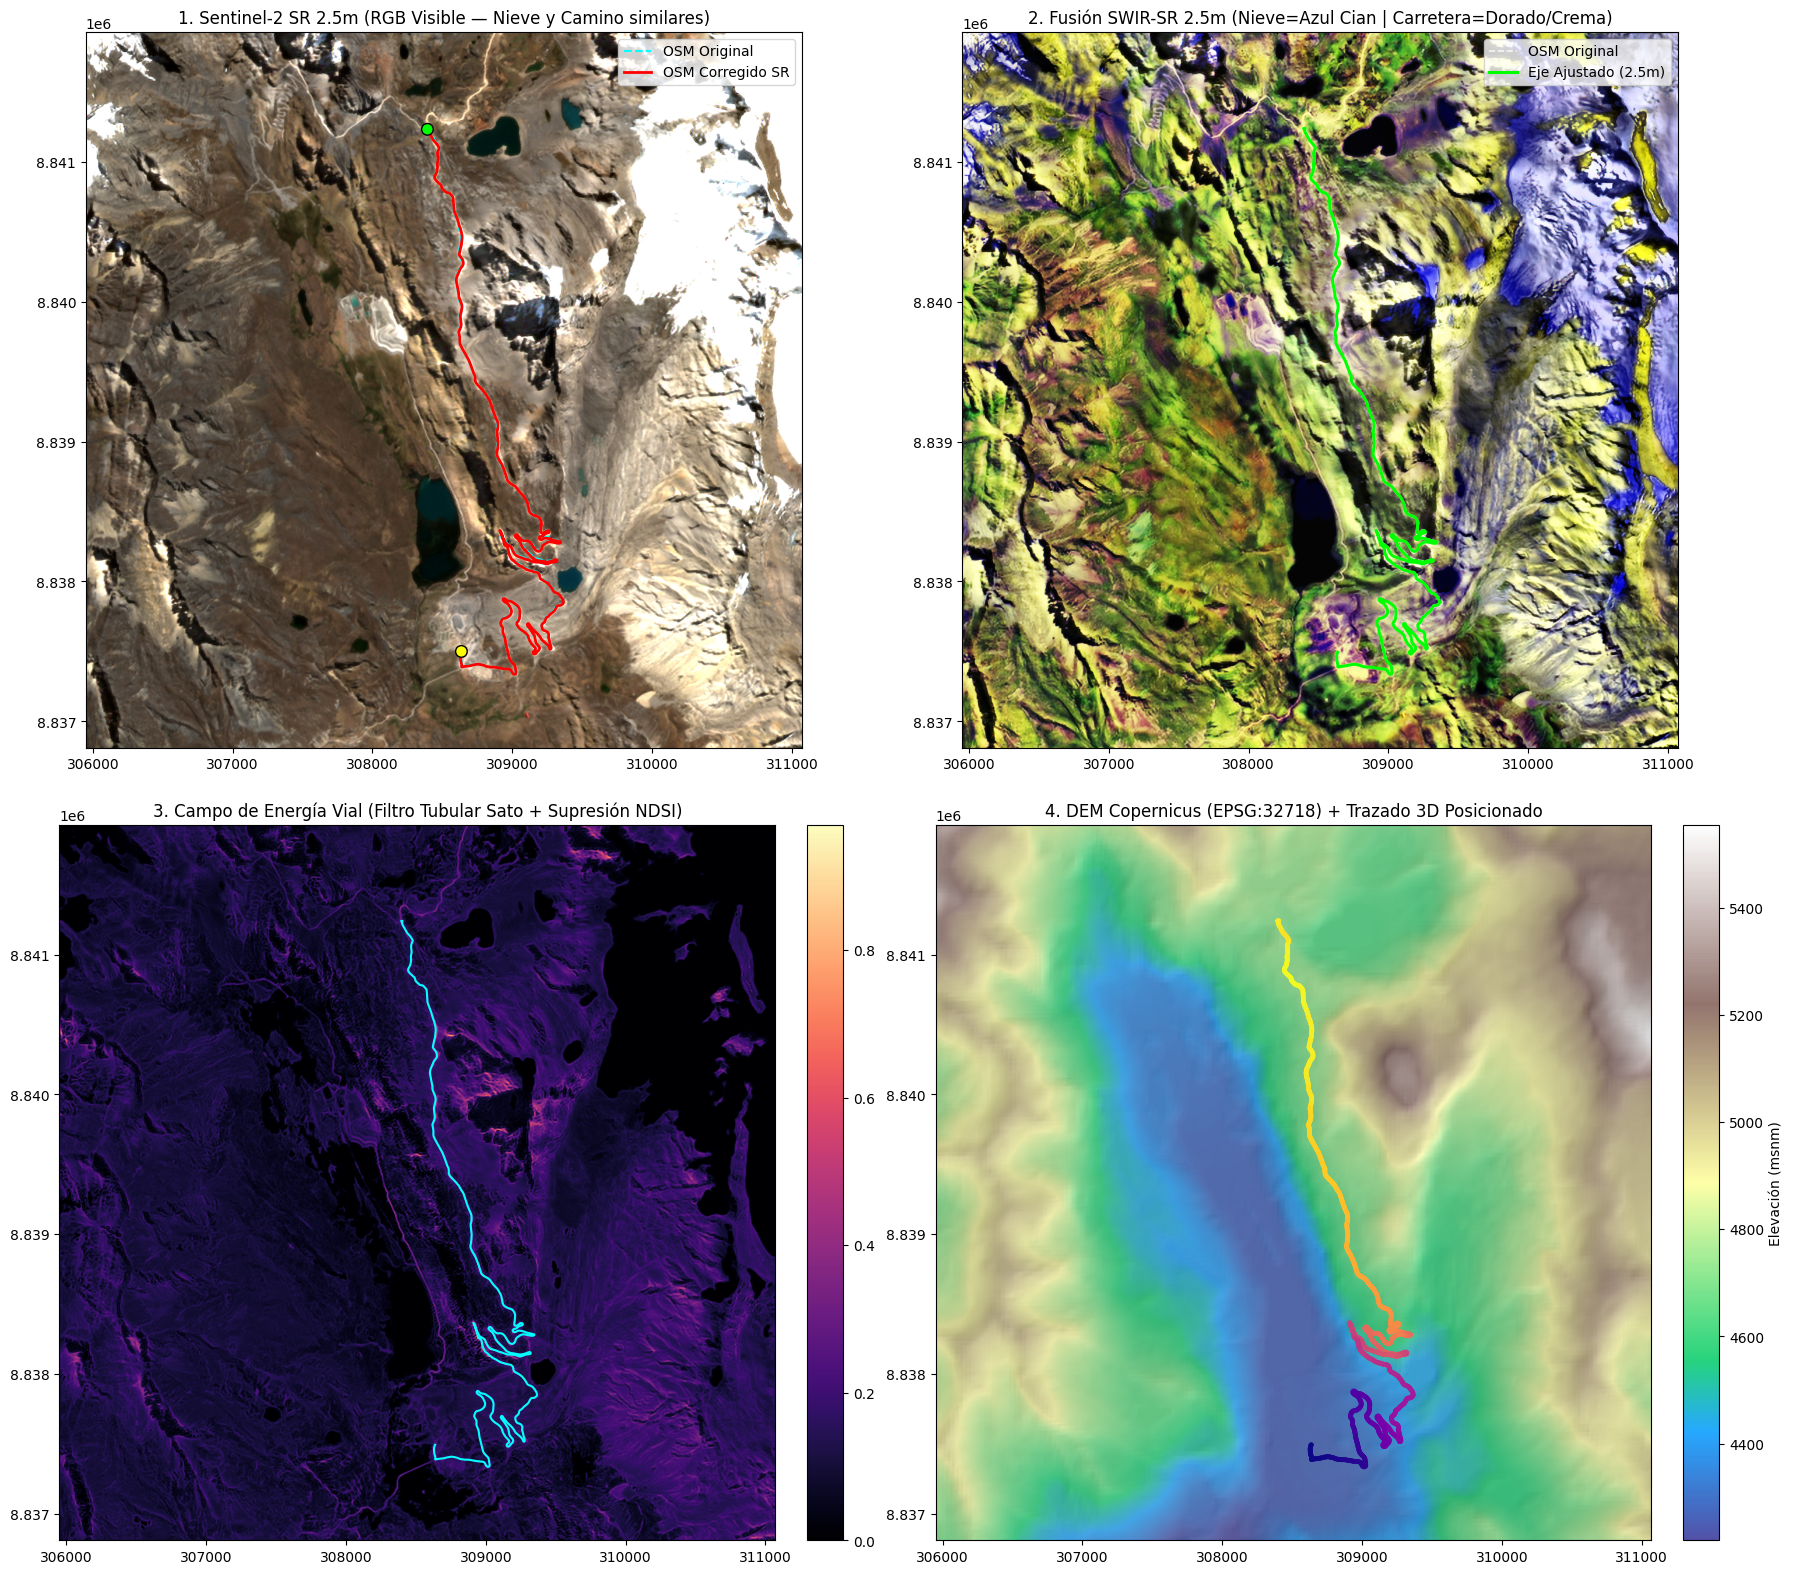

In [13]:
#@title 8. Visualización Diagnóstica Completa (RGB vs SWIR Anti-Nieve + DEM + Corrección OSM)
import matplotlib.pyplot as plt

def rgb_falso_display(chw, white=0.32):
    rgb = np.moveaxis(chw[:3], 0, -1)
    return np.clip(rgb / white, 0.0, 1.0) ** (1.0 / 1.1)

extent_utm = [x_izq, x_der, y_abajo, y_arriba]

fig, axs = plt.subplots(2, 2, figsize=(18, 16))

# 1. RGB Super-Resuelto Estándar
axs[0, 0].imshow(rgb_falso_display(sr), extent=extent_utm)
axs[0, 0].plot(pts_osm[:, 0], pts_osm[:, 1], "--", color="cyan", lw=1.5, label="OSM Original")
axs[0, 0].plot(pts_corregidos_xy[:, 0], pts_corregidos_xy[:, 1], "-", color="red", lw=2.0, label="OSM Corregido SR")
axs[0, 0].scatter([salida_x, llegada_x], [salida_y, llegada_y], c=["lime", "yellow"], s=70, zorder=5, edgecolors="black")
axs[0, 0].set_title("1. Sentinel-2 SR 2.5m (RGB Visible — Nieve y Camino similares)")
axs[0, 0].legend(loc="upper right")

# 2. Fusión SWIR Anti-Nieve
axs[0, 1].imshow(img_antinieve_rgb, extent=extent_utm)
axs[0, 1].plot(pts_osm[:, 0], pts_osm[:, 1], "--", color="white", lw=1.2, alpha=0.8, label="OSM Original")
axs[0, 1].plot(pts_corregidos_xy[:, 0], pts_corregidos_xy[:, 1], "-", color="#00FF00", lw=2.2, label="Eje Ajustado (2.5m)")
axs[0, 1].set_title("2. Fusión SWIR-SR 2.5m (Nieve=Azul Cian | Carretera=Dorado/Crema)")
axs[0, 1].legend(loc="upper right")

# 3. Mapa de Energía Tubular (Sato + Anti-NDSI)
im3 = axs[1, 0].imshow(mapa_energia_camino, extent=extent_utm, cmap="magma")
axs[1, 0].plot(pts_corregidos_xy[:, 0], pts_corregidos_xy[:, 1], "-", color="cyan", lw=1.5, label="Eje Capturado")
axs[1, 0].set_title("3. Campo de Energía Vial (Filtro Tubular Sato + Supresión NDSI)")
plt.colorbar(im3, ax=axs[1, 0], fraction=0.046, pad=0.04)

# 4. DEM + Sombreado Hillshade + Perfil 3D
gy, gx = np.gradient(dem_2p5m, RES_SR, RES_SR)
hillshade = np.clip(((-gx - gy) / (np.hypot(gx, gy) + 10.0) + 1.0) * 0.5, 0.0, 1.0)
im4 = axs[1, 1].imshow(dem_2p5m, extent=extent_utm, cmap="terrain", alpha=0.85)
axs[1, 1].imshow(hillshade, extent=extent_utm, cmap="gray", alpha=0.25)
sc = axs[1, 1].scatter(pts_corregidos_xy[:, 0], pts_corregidos_xy[:, 1], c=z_perfil_preservado, cmap="plasma", s=6, label="Cota Z Carretera")
axs[1, 1].set_title("4. DEM Copernicus (EPSG:32718) + Trazado 3D Posicionado")
plt.colorbar(im4, ax=axs[1, 1], fraction=0.046, pad=0.04, label="Elevación (msnm)")

plt.tight_layout()
diag_png = ROOT / f"{prefix}_diagnostico_integral.png"
plt.savefig(diag_png, dpi=180)
plt.show()

In [14]:
#@title 9. Exportar Todos los Artefactos Finales (DEM, GeoTIFFs Mejorados, Carretera 3D y Metadata)
import json, csv
from PIL import Image
from zipfile import ZipFile, ZIP_DEFLATED

# --- Rutas de salida ---
tif_s2_10m       = ROOT / f"{prefix}_S2_10m_RGBN.tif"
tif_sr_2p5m      = ROOT / f"{prefix}_SR_2p5m_RGBN.tif"
tif_swir_enh     = ROOT / f"{prefix}_SR_2p5m_AntiNieve_SWIR_RGB.tif"
tif_road_energy  = ROOT / f"{prefix}_SR_2p5m_Mapa_Energia_Carretera.tif"
tif_ndsi_2p5m    = ROOT / f"{prefix}_SR_2p5m_NDSI_MascaraNieve.tif"
tif_dem_10m      = ROOT / f"{prefix}_DEM_GLO30_10m_float32.tif"
tif_dem_2p5m     = ROOT / f"{prefix}_DEM_Suavizado_2p5m_float32.tif"
png_antinieve    = ROOT / f"{prefix}_Textura_AntiNieve_2p5m.png"
png_rgb_sr       = ROOT / f"{prefix}_Textura_RGB_SR_2p5m.png"
geojson_utm_3d   = ROOT / f"{prefix}_Carretera_Corregida_3D_UTM18S.geojson"
geojson_wgs_3d   = ROOT / f"{prefix}_Carretera_Corregida_3D_WGS84.geojson"
csv_spline_3d    = ROOT / f"{prefix}_Carretera_Spline_3D_Nodes.csv"
json_metadata    = ROOT / f"{prefix}_metadata_geografica.json"

def guardar_geotiff(ruta, array_chw, transform_aff, descripciones=None, nodata_val=None):
    if array_chw.ndim == 2:
        array_chw = array_chw[None, ...]
    c, h, w = array_chw.shape
    with rasterio.open(
        ruta, "w", driver="GTiff", height=h, width=w, count=c,
        dtype="float32", crs=CRS_METRICO, transform=transform_aff,
        tiled=True, compress="deflate", predictor=3, nodata=nodata_val
    ) as dst:
        dst.write(array_chw.astype("float32"))
        if descripciones:
            dst.descriptions = tuple(descripciones)

# 1. Guardar GeoTIFFs Satelitales y Índices
guardar_geotiff(tif_s2_10m, x_s2, transform_10m, ["B04_Red", "B03_Green", "B02_Blue", "B08_NIR"])
guardar_geotiff(tif_sr_2p5m, sr, transform_2p5m, ["SR_B04", "SR_B03", "SR_B02", "SR_B08"])
guardar_geotiff(tif_swir_enh, np.moveaxis(img_antinieve_rgb, -1, 0), transform_2p5m, ["SWIR_B12_Enh", "SWIR_B11_Enh", "Blue_B02_Enh"])
guardar_geotiff(tif_road_energy, mapa_energia_camino, transform_2p5m, ["Road_Tubular_Likelihood"])
guardar_geotiff(tif_ndsi_2p5m, ndsi_2p5m, transform_2p5m, ["NDSI_Snow_Index"])

# 2. Guardar DEMs en float32
guardar_geotiff(tif_dem_10m, dem_10m, transform_10m, ["Elevation_m_ASL_10m"])
guardar_geotiff(tif_dem_2p5m, dem_2p5m, transform_2p5m, ["Elevation_m_ASL_2p5m_C2"])

# 3. Guardar Texturas PNG de 8-bit para visualización directa en Blender / Godot
Image.fromarray((img_antinieve_rgb * 255).round().clip(0, 255).astype("uint8")).save(png_antinieve)
Image.fromarray((rgb_falso_display(sr) * 255).round().clip(0, 255).astype("uint8")).save(png_rgb_sr)

# 4. Construir Geometrías 3D (X, Y, Z) y exportar GeoJSON en EPSG:32718 y EPSG:4326
linea_osm_orig_3d = LineString([(pts_osm[i, 0], pts_osm[i, 1], float(z_perfil_preservado[i])) for i in range(len(pts_osm))])
linea_corr_3d_preservada = LineString([(pts_corregidos_xy[i, 0], pts_corregidos_xy[i, 1], float(z_perfil_preservado[i])) for i in range(len(pts_osm))])
linea_corr_3d_dem_local  = LineString([(pts_corregidos_xy[i, 0], pts_corregidos_xy[i, 1], float(z_perfil_dem_local[i])) for i in range(len(pts_osm))])

gdf_3d = gpd.GeoDataFrame(
    {
        "id_capa": ["osm_original_3d", "osm_corregido_sr_z_preservado", "osm_corregido_sr_z_dem_local"],
        "descripcion": [
            "Trazado horizontal OSM original con cota Z del DEM",
            "Trazado horizontal ajustado a imagen SR/SWIR 2.5m conservando perfil vertical original",
            "Trazado horizontal ajustado a imagen SR/SWIR 2.5m con muestreo Z directo en nueva coordenada"
        ],
        "longitud_2d_m": [float(linea_osm_orig_3d.length), float(linea_corr_3d_preservada.length), float(linea_corr_3d_dem_local.length)],
        "cota_inicio_m": [float(z_perfil_preservado[0])] * 3,
        "cota_fin_m": [float(z_perfil_preservado[-1])] * 3,
    },
    geometry=[linea_osm_orig_3d, linea_corr_3d_preservada, linea_corr_3d_dem_local],
    crs=CRS_METRICO
)
gdf_3d.to_file(geojson_utm_3d, driver="GeoJSON")
gdf_3d.to_crs("EPSG:4326").to_file(geojson_wgs_3d, driver="GeoJSON")

# 5. Exportar Tabla CSV de Nodos 3D (Lista para importar en Godot / Blender Geometry Nodes)
lons_corr, lats_corr = utm_to_wgs.transform(pts_corregidos_xy[:, 0], pts_corregidos_xy[:, 1])
with open(csv_spline_3d, "w", newline="", encoding="utf-8") as f_csv:
    writer = csv.writer(f_csv)
    writer.writerow([
        "node_idx", "s_orig_m", "s_corr_m",
        "x_utm_orig", "y_utm_orig",
        "x_utm_corr", "y_utm_corr",
        "lon_wgs84_corr", "lat_wgs84_corr",
        "z_preservado_m", "z_dem_local_m",
        "delta_lateral_m", "pendiente_pct", "curvatura_1_m", "confianza_vial"
    ])
    for i in range(len(pts_osm)):
        writer.writerow([
            i,
            round(float(s_dist[i]), 3),
            round(float(ds_nuevo[i]), 3),
            round(float(pts_osm[i, 0]), 3),
            round(float(pts_osm[i, 1]), 3),
            round(float(pts_corregidos_xy[i, 0]), 3),
            round(float(pts_corregidos_xy[i, 1]), 3),
            round(float(lons_corr[i]), 7),
            round(float(lats_corr[i]), 7),
            round(float(z_perfil_preservado[i]), 3),
            round(float(z_perfil_dem_local[i]), 3),
            round(float(delta_normal_suave[i]), 3),
            round(float(pendiente_pct[i]), 3),
            round(float(curvatura_k[i]), 6),
            round(float(confianza_vial[i]), 4),
        ])

# 6. Exportar Metadata Geográfica Integral
metadata = {
    "project": "Stage Rally Nevado Raura - Cantera Quichas",
    "crs_metric": CRS_METRICO,
    "crs_geographic": "EPSG:4326",
    "stage_endpoints": {
        "start_raura": {"lat": SALIDA_LAT, "lon": SALIDA_LON, "utm_x": round(salida_x, 3), "utm_y": round(salida_y, 3), "z_m": round(float(z_perfil_preservado[0]), 2)},
        "finish_quichas": {"lat": LLEGADA_LAT, "lon": LLEGADA_LON, "utm_x": round(llegada_x, 3), "utm_y": round(llegada_y, 3), "z_m": round(float(z_perfil_preservado[-1]), 2)}
    },
    "bounding_box_utm18s": {"xmin": x_izq, "ymin": y_abajo, "xmax": x_der, "ymax": y_arriba},
    "bounding_box_wgs84": list(bbox_wgs84),
    "affine_transforms_gdal": {
        "grid_10m": list(transform_10m.to_gdal()),
        "grid_2p5m": list(transform_2p5m.to_gdal())
    },
    "sentinel2_scene": {
        "stac_id": seleccionado.id,
        "datetime_utc": seleccionado.datetime.isoformat(),
        "local_cloud_pct": round(float(NUBES_LOCAL), 2),
        "local_snow_pct": round(float(NIEVE_LOCAL), 2),
        "radiometric_scale_offset": metadatos_radiometricos
    },
    "dem_source": {
        "collection": COLECCION_DEM,
        "tiles_used": [it.id for it in items_dem],
        "min_elevation_m": round(float(dem_2p5m.min()), 2),
        "max_elevation_m": round(float(dem_2p5m.max()), 2)
    },
    "road_alignment_metrics": {
        "spline_step_m": PASO_SPLINE_M,
        "total_nodes": int(len(pts_osm)),
        "length_2d_osm_orig_m": round(float(linea_osm_2d.length), 2),
        "length_2d_sr_corrected_m": round(float(ds_nuevo[-1]), 2),
        "mean_lateral_correction_m": round(float(np.abs(delta_normal_suave).mean()), 3),
        "max_lateral_correction_m": round(float(np.abs(delta_normal_suave).max()), 3)
    }
}
json_metadata.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

# 7. Empaquetar Todo en un ZIP Descargable
archivos_exportados = [
    tif_s2_10m, tif_sr_2p5m, tif_swir_enh, tif_road_energy, tif_ndsi_2p5m,
    tif_dem_10m, tif_dem_2p5m, png_antinieve, png_rgb_sr, diag_png,
    geojson_utm_3d, geojson_wgs_3d, csv_spline_3d, json_metadata
]

zip_final = ROOT / f"{prefix}_Stage_Completo_3D.zip"
with ZipFile(zip_final, "w", ZIP_DEFLATED, compresslevel=5) as zf:
    for f_path in archivos_exportados:
        zf.write(f_path, arcname=f_path.name)
        print(f"[OK] {f_path.name} ({f_path.stat().st_size // 1024} KiB)")

print(f"\n=== PAQUETE FINAL GENERADO: {zip_final.name} ({zip_final.stat().st_size / (1024*1024):.2f} MiB) ===")
try:
    from google.colab import files
    files.download(str(zip_final))
except ImportError:
    print("Ejecución local completada. Archivo en:", zip_final)

[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_S2_10m_RGBN.tif (3160 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_SR_2p5m_RGBN.tif (47428 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_SR_2p5m_AntiNieve_SWIR_RGB.tif (33530 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_SR_2p5m_Mapa_Energia_Carretera.tif (11865 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_SR_2p5m_NDSI_MascaraNieve.tif (11236 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_DEM_GLO30_10m_float32.tif (517 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_DEM_Suavizado_2p5m_float32.tif (5951 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_Textura_AntiNieve_2p5m.png (6075 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_Textura_RGB_SR_2p5m.png (4828 KiB)
[OK] raura_quichas_20260807_S2B_T18LUP_20260807T152351_L2A_diagnostico_integral.png (9859 KiB)
[OK] raura_quichas_20260807_S2B_T18

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>